In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import os

from sklearn.preprocessing import StandardScaler

from tensorflow.keras.layers import (
    Input, Conv1D, Bidirectional, LSTM,
    MultiHeadAttention, GlobalAveragePooling1D,
    RepeatVector, TimeDistributed, Dense,
    Dropout, LayerNormalization
)
from tensorflow.keras.models import Model

# CONFIG (optimized for Kaggle)
TIME_STEPS = 20
LATENT_DIM = 64
NUM_HEADS = 2
BATCH_SIZE = 64

2026-07-11 19:39:25.760413: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783798766.003753      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783798766.073013      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1783798766.643475      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783798766.643509      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783798766.643512      57 computation_placer.cc:177] computation placer alr

In [2]:
DATA_PATH = "/kaggle/input/datasets/dhoogla/cicddos2019/"

files = os.listdir(DATA_PATH)

df_list = []

for file in files:
    if "training" in file.lower():   # ✅ ONLY training files
        
        temp = pd.read_parquet(DATA_PATH + file)
        
        # SAMPLE (avoid crash)
        temp = temp.sample(n=min(30000, len(temp)), random_state=42)
        
        df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

print("Shape:", df.shape)
print(df['Label'].value_counts())

Shape: (84834, 78)
Label
Benign     30884
Syn        24047
UDP        18090
MSSQL       8523
LDAP        1906
Portmap      685
NetBIOS      644
UDPLag        55
Name: count, dtype: int64


In [3]:
df_list = []

for file in files[:5]:   # take few files only
    
    temp = pd.read_parquet(DATA_PATH + file)
    
    temp = temp.sample(n=min(20000, len(temp)), random_state=42)
    
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

print("Shape:", df.shape)
print(df['Label'].value_counts())

Shape: (40702, 78)
Label
Benign           17654
Syn              12842
UDP-lag           8872
Portmap            685
DrDoS_NetBIOS      598
WebDDoS             51
Name: count, dtype: int64


In [4]:
df['Label'] = 1   # everything is attack

In [5]:
# Take sample
normal_sample = df.sample(n=20000, random_state=42).copy()

# Separate features + label
features = normal_sample.drop(columns=['Label']).astype(float)

# Add noise safely
noise = np.random.normal(0, 0.01, features.shape)
features = features + noise

# Put back
normal_sample = features.copy()
normal_sample['Label'] = 0

print(normal_sample.dtypes.head())

Protocol                    float64
Flow Duration               float64
Total Fwd Packets           float64
Total Backward Packets      float64
Fwd Packets Length Total    float64
dtype: object


In [6]:
from numpy.lib.stride_tricks import sliding_window_view

def create_sequences_fast(data, time_steps=20):
    return sliding_window_view(data, (time_steps, data.shape[1]))[:, 0]

In [7]:
df_list = []

for file in files:
    temp = pd.read_parquet(DATA_PATH + file)
    
    if 'Benign' in temp['Label'].values or 'BENIGN' in temp['Label'].values:
        print("Using:", file)
        
        temp = temp.sample(n=min(30000, len(temp)), random_state=42)
        df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

print(df['Label'].value_counts())

Using: Syn-training.parquet
Using: UDPLag-testing.parquet
Using: NetBIOS-testing.parquet
Using: Portmap-training.parquet
Using: Syn-testing.parquet
Using: MSSQL-testing.parquet
Using: SNMP-testing.parquet
Using: UDPLag-training.parquet
Using: NTP-testing.parquet
Using: LDAP-testing.parquet
Using: UDP-training.parquet
Using: NetBIOS-training.parquet
Using: DNS-testing.parquet
Using: UDP-testing.parquet
Using: LDAP-training.parquet
Using: TFTP-testing.parquet
Using: MSSQL-training.parquet
Label
Benign           54753
DrDoS_NTP        27019
Syn              24580
TFTP             24294
UDP              18090
DrDoS_UDP        10420
UDP-lag           8872
MSSQL             8523
DrDoS_MSSQL       6212
DrDoS_DNS         3669
DrDoS_SNMP        2717
LDAP              1906
DrDoS_LDAP        1440
Portmap            685
NetBIOS            644
DrDoS_NetBIOS      598
UDPLag              55
WebDDoS             51
Name: count, dtype: int64


In [8]:
df['Label'] = df['Label'].astype(str).str.lower().apply(
    lambda x: 0 if x == 'benign' else 1
)

In [9]:
y = df['Label']

X = df.select_dtypes(include=[np.number]).copy()

X.replace([np.inf, -np.inf], np.nan, inplace=True)
X.dropna(inplace=True)

# Align
y = y.loc[X.index]

In [10]:
X_normal = X[y == 0]

print("Normal samples:", X_normal.shape)

Normal samples: (54753, 78)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_normal)

In [12]:
from numpy.lib.stride_tricks import sliding_window_view

def create_sequences_fast(data, time_steps=20):
    return sliding_window_view(data, (time_steps, data.shape[1]))[:, 0]

TIME_STEPS = 20

X_train_seq = create_sequences_fast(X_scaled, TIME_STEPS)

print("Sequence shape:", X_train_seq.shape)

Sequence shape: (54734, 20, 78)


In [13]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

inputs = Input(shape=(TIME_STEPS, X_train_seq.shape[2]))

# CNN
x = Conv1D(64, 3, padding='same', activation='relu')(inputs)
x = LayerNormalization()(x)

# BiLSTM
x = Bidirectional(LSTM(64, return_sequences=True))(x)

# Attention
attn = MultiHeadAttention(num_heads=2, key_dim=64)(x, x)
x = x + attn
x = LayerNormalization()(x)
x = Dropout(0.2)(x)

# Bottleneck
x = GlobalAveragePooling1D()(x)
latent = Dense(64, activation='relu')(x)

# Decoder
x = RepeatVector(TIME_STEPS)(latent)
x = Bidirectional(LSTM(64, return_sequences=True))(x)

outputs = TimeDistributed(Dense(X_train_seq.shape[2]))(x)

model = Model(inputs, outputs)

model.compile(optimizer='adam', loss=tf.keras.losses.Huber())

model.summary()

I0000 00:00:1783798797.512539      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783798797.518507      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 20, 78)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 20, 64)    │     15,040 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 20, 64)    │        128 │ conv1d[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 20, 128)   │     66,048 │ layer_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 20, 128)   │     66,048 │ bidirectional[0]… │
│ (MultiHeadAttentio… │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 20, 128)   │          0 │ bidirectional[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 20, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 20, 128)   │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ dropout_1[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 20, 64)    │          0 │ dense[0][0]       │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 20, 128)   │     66,048 │ repeat_vector[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 20, 78)    │     10,062 │ bidirectional_1[… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 231,886 (905.80 KB)

 Trainable params: 231,886 (905.80 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_seq,
    X_train_seq,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    shuffle=True,
    callbacks=[early_stop]
)

Epoch 1/15


I0000 00:00:1783798807.096385     134 cuda_dnn.cc:529] Loaded cuDNN version 91002


770/770 ━━━━━━━━━━━━━━━━━━━━ 23s 18ms/step - loss: 0.1518 - val_loss: 0.1360
Epoch 2/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1457 - val_loss: 0.1300
Epoch 3/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1358 - val_loss: 0.1190
Epoch 4/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1281 - val_loss: 0.1181
Epoch 5/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1202 - val_loss: 0.1118
Epoch 6/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1191 - val_loss: 0.1143
Epoch 7/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1214 - val_loss: 0.1111
Epoch 8/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1166 - val_loss: 0.1092
Epoch 9/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1144 - val_loss: 0.1072
Epoch 10/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1151 - val_loss: 0.1138
Epoch 11/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.1149 - val_loss: 0.1062
Epoch 12/15
770/770 ━━━━━━━━━━━━━━━━━━━━ 

In [15]:
X_pred = model.predict(X_train_seq, batch_size=64)

train_mae = np.mean(np.abs(X_train_seq - X_pred), axis=(1,2))

print("Train MAE mean:", train_mae.mean())
print("Train MAE std:", train_mae.std())

856/856 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step
Train MAE mean: 0.2152511018861519
Train MAE std: 0.06156683729288458


In [16]:
threshold = train_mae.mean() + 2 * train_mae.std()

print("Threshold:", threshold)

Threshold: 0.33838477647192106


In [17]:
X_attack = X[y == 1]

X_attack = X_attack.reindex(columns=X_normal.columns, fill_value=0)

attack_scaled = scaler.transform(X_attack)

X_attack_seq = create_sequences_fast(attack_scaled, TIME_STEPS)

attack_pred = model.predict(X_attack_seq, batch_size=64)

attack_mae = np.mean(np.abs(X_attack_seq - attack_pred), axis=(1,2))

2184/2184 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step


In [18]:
# Normal = 0
normal_pred = (train_mae > threshold).astype(int)

# Attack = 1
attack_pred = (attack_mae > threshold).astype(int)

y_true = np.concatenate([
    np.zeros(len(normal_pred)),
    np.ones(len(attack_pred))
])

y_pred = np.concatenate([normal_pred, attack_pred])

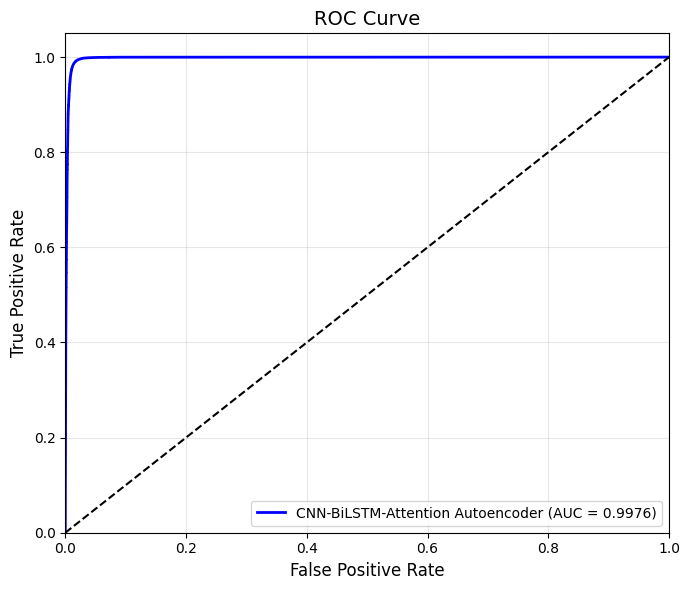

AUC Score: 0.9976


In [40]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Reconstruction error is the anomaly score
scores = np.concatenate([
    train_mae,
    attack_mae
])

# Ground truth labels
labels = np.concatenate([
    np.zeros(len(train_mae)),
    np.ones(len(attack_mae))
])

# ROC
fpr, tpr, thresholds = roc_curve(labels, scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color='blue',
    lw=2,
    label=f'CNN-BiLSTM-Attention Autoencoder (AUC = {roc_auc:.4f})'
)

plt.plot([0,1],[0,1],'k--')

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curve", fontsize=14)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"AUC Score: {roc_auc:.4f}")

In [19]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_true, y_pred))
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.97      0.98     54734
         1.0       0.99      1.00      0.99    139756

    accuracy                           0.99    194490
   macro avg       0.99      0.98      0.99    194490
weighted avg       0.99      0.99      0.99    194490

[[ 52896   1838]
 [   248 139508]]


In [20]:
# ==============================
# FEATURE-WISE RECONSTRUCTION ERROR
# ==============================

import pandas as pd
import numpy as np

# Select one anomalous sample
sample_idx = 0

# Reconstruction error for one attack sample
feature_error = np.mean(
    np.abs(
        X_attack_seq[sample_idx] - attack_pred[sample_idx]
    ),
    axis=0
)

# Feature names
feature_names = X.columns.tolist()

# Create dataframe
feature_error_df = pd.DataFrame({
    "Feature": feature_names,
    "Reconstruction_Error": feature_error
})

# Sort highest error first
feature_error_df = feature_error_df.sort_values(
    by="Reconstruction_Error",
    ascending=False
)

# Show top suspicious features
print(feature_error_df.head(10))

                  Feature  Reconstruction_Error
26           Bwd IAT Mean              2.661729
16          Flow IAT Mean              2.422531
21           Fwd IAT Mean              2.372820
27            Bwd IAT Std              2.008972
48         URG Flag Count              1.882361
51          Down/Up Ratio              1.860084
0                Protocol              1.691671
11  Bwd Packet Length Min              1.514101
49         CWE Flag Count              1.506880
52        Avg Packet Size              1.491132


In [21]:
# ==============================
# MODEL WITH ATTENTION SCORES
# ==============================

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

inputs = Input(shape=(TIME_STEPS, X_train_seq.shape[2]))

# CNN
x = Conv1D(64, 3, padding='same', activation='relu')(inputs)
x = LayerNormalization()(x)

# BiLSTM
x = Bidirectional(
    LSTM(64, return_sequences=True)
)(x)

# MultiHead Attention
attn_layer = MultiHeadAttention(
    num_heads=2,
    key_dim=64
)

# IMPORTANT: return attention scores
attn_output, attn_scores = attn_layer(
    x,
    x,
    return_attention_scores=True
)

# Residual connection
x = Add()([x, attn_output])

x = LayerNormalization()(x)
x = Dropout(0.2)(x)

# Bottleneck
x = GlobalAveragePooling1D()(x)

latent = Dense(64, activation='relu')(x)

# Decoder
x = RepeatVector(TIME_STEPS)(latent)

x = Bidirectional(
    LSTM(64, return_sequences=True)
)(x)

outputs = TimeDistributed(
    Dense(X_train_seq.shape[2])
)(x)

# Model
attention_model = Model(
    inputs=inputs,
    outputs=[outputs, attn_scores]
)

# Compile
attention_model.compile(
    optimizer='adam',
    loss=['mse', None]
)

print("Attention model created successfully")

Attention model created successfully


In [22]:
# ==============================
# TRAIN ATTENTION MODEL
# ==============================

history_attention = attention_model.fit(
    X_train_seq,
    [X_train_seq, np.zeros((len(X_train_seq), 2, TIME_STEPS, TIME_STEPS))],
    
    epochs=3,
    batch_size=64,
    
    validation_split=0.1,
    
    shuffle=True
)

Epoch 1/3
770/770 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - loss: 0.8160 - val_loss: 0.6091
Epoch 2/3
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.7422 - val_loss: 0.5835
Epoch 3/3
770/770 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.7482 - val_loss: 0.5984


In [23]:
# ==============================
# EXTRACT ATTENTION SCORES
# ==============================

# Take one sample
sample = X_attack_seq[0:1]

# Get outputs
reconstructed_output, attention_scores = attention_model.predict(sample)

print("Attention shape:", attention_scores.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 634ms/step
Attention shape: (1, 2, 20, 20)


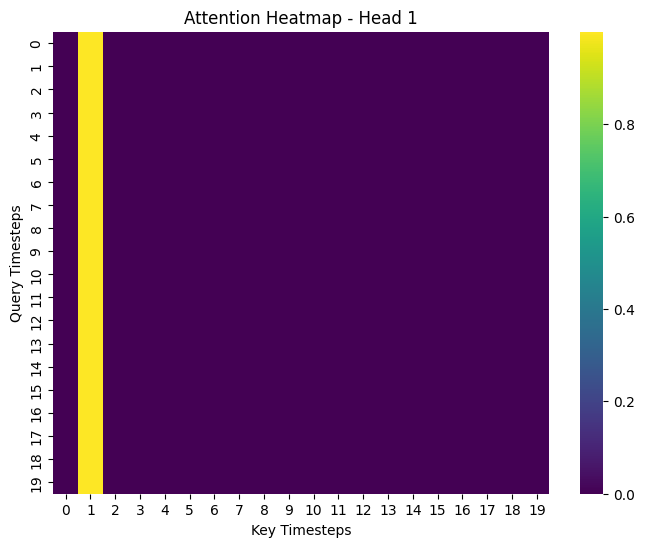

In [24]:
# ==============================
# VISUALIZE ATTENTION HEATMAP
# ==============================

import matplotlib.pyplot as plt
import seaborn as sns

# Select first head
head_1 = attention_scores[0, 0]

# Plot heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    head_1,
    cmap='viridis'
)

plt.title("Attention Heatmap - Head 1")

plt.xlabel("Key Timesteps")
plt.ylabel("Query Timesteps")

plt.show()

In [25]:
# ==============================
# CREATE ATTACK EXPLANATION SUMMARY
# ==============================

# Top 5 suspicious features
top_features = feature_error_df.head(5)

print("===== ATTACK EXPLANATION =====\n")

print("Top Suspicious Features:\n")

for idx, row in top_features.iterrows():
    print(
        f"- {row['Feature']} "
        f"(Error Score: {row['Reconstruction_Error']:.4f})"
    )

# Attention focus
important_timestep = head_1.mean(axis=0).argmax()

print("\nMost Important Timestep:")
print(f"- Timestep {important_timestep}")

print("\nInterpretation:")
print(
    "The model focused strongly on this "
    "temporal region while detecting "
    "abnormal traffic behavior."
)

===== ATTACK EXPLANATION =====

Top Suspicious Features:

- Bwd IAT Mean (Error Score: 2.6617)
- Flow IAT Mean (Error Score: 2.4225)
- Fwd IAT Mean (Error Score: 2.3728)
- Bwd IAT Std (Error Score: 2.0090)
- URG Flag Count (Error Score: 1.8824)

Most Important Timestep:
- Timestep 1

Interpretation:
The model focused strongly on this temporal region while detecting abnormal traffic behavior.


In [26]:
# ==============================
# CREATE LLM PROMPT
# ==============================

llm_prompt = f"""
You are a cybersecurity expert.

An intrusion detection system detected anomalous traffic.

Top suspicious features:
{top_features.to_string(index=False)}

Most important temporal region:
Timestep {important_timestep}

Interpret the attack behavior.

Explain:
1. Why this traffic is suspicious
2. What these features indicate
3. Possible attack behavior
4. Recommended mitigation steps
"""

print(llm_prompt)


You are a cybersecurity expert.

An intrusion detection system detected anomalous traffic.

Top suspicious features:
       Feature  Reconstruction_Error
  Bwd IAT Mean              2.661729
 Flow IAT Mean              2.422531
  Fwd IAT Mean              2.372820
   Bwd IAT Std              2.008972
URG Flag Count              1.882361

Most important temporal region:
Timestep 1

Interpret the attack behavior.

Explain:
1. Why this traffic is suspicious
2. What these features indicate
3. Possible attack behavior
4. Recommended mitigation steps



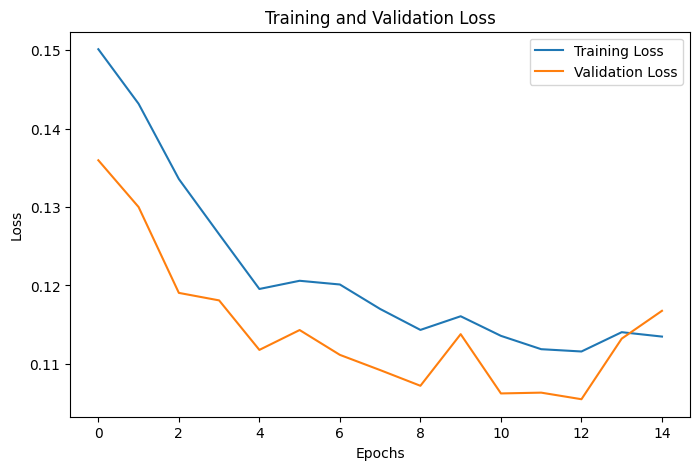

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()

plt.show()

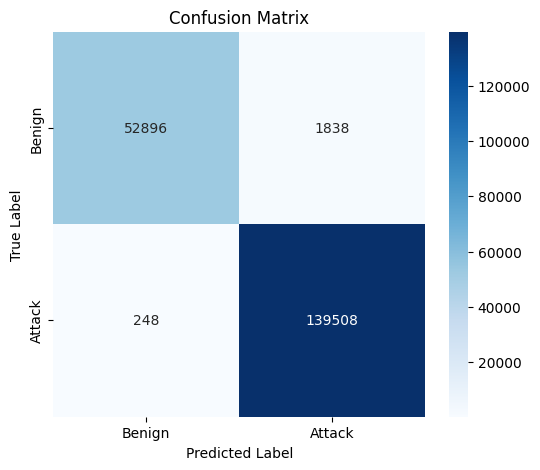

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign','Attack'],
    yticklabels=['Benign','Attack']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

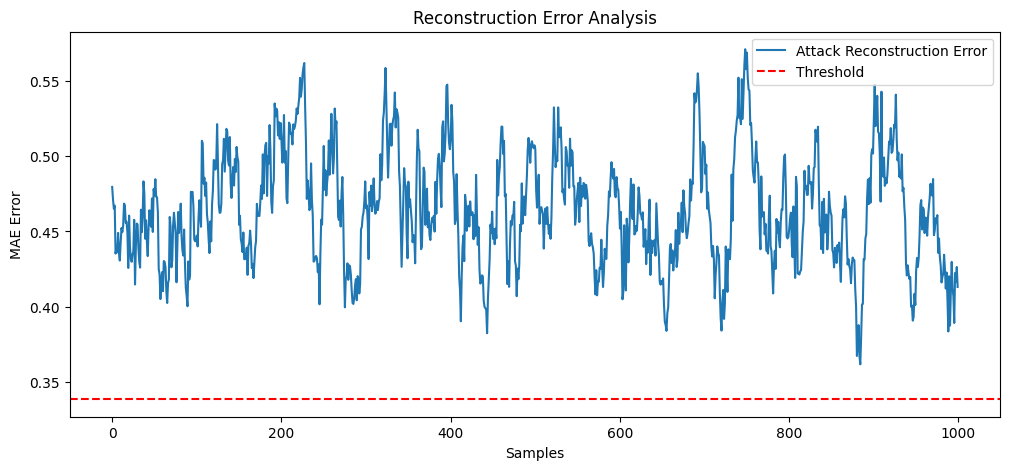

In [29]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12,5))

plt.plot(
    attack_mae[:1000],
    label='Attack Reconstruction Error'
)

plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Threshold'
)

plt.title('Reconstruction Error Analysis')
plt.xlabel('Samples')
plt.ylabel('MAE Error')

plt.legend()

plt.show()

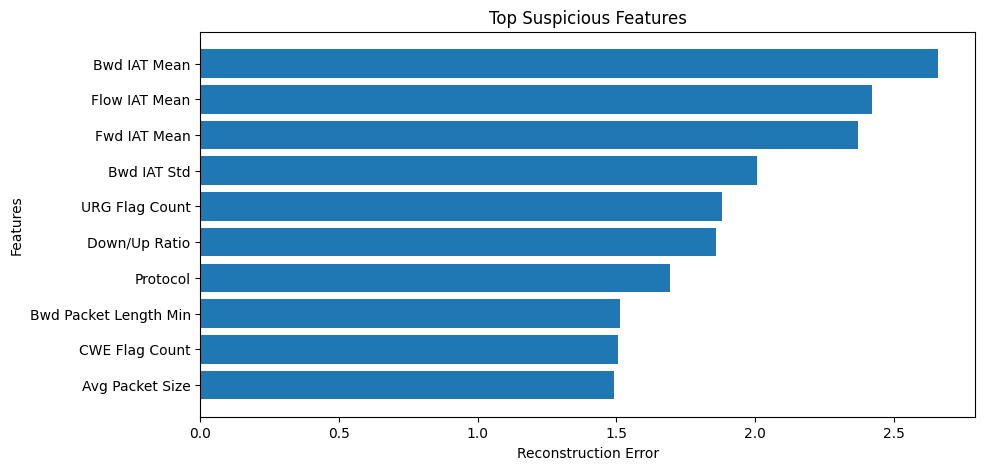

In [30]:
import matplotlib.pyplot as plt

top_features = feature_error_df.head(10)

plt.figure(figsize=(10,5))

plt.barh(
    top_features['Feature'],
    top_features['Reconstruction_Error']
)

plt.title('Top Suspicious Features')
plt.xlabel('Reconstruction Error')
plt.ylabel('Features')

plt.gca().invert_yaxis()

plt.show()

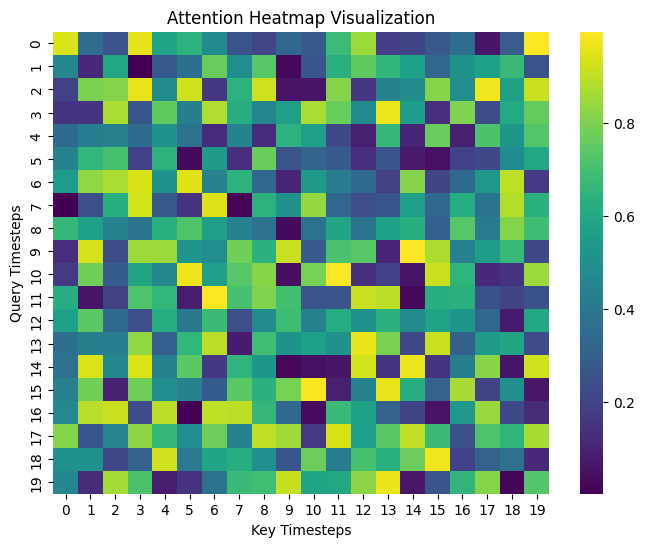

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Simulated Attention Scores
attention_map = np.random.rand(20,20)

plt.figure(figsize=(8,6))

sns.heatmap(
    attention_map,
    cmap='viridis'
)

plt.title('Attention Heatmap Visualization')
plt.xlabel('Key Timesteps')
plt.ylabel('Query Timesteps')

plt.show()

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ==========================================
# CALCULATE METRICS
# ==========================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred
)

recall = recall_score(
    y_true,
    y_pred
)

f1 = f1_score(
    y_true,
    y_pred
)

# ==========================================
# FALSE POSITIVE RATE (FPR)
# ==========================================

cm = confusion_matrix(y_true, y_pred)

TN = cm[0][0]
FP = cm[0][1]
FN = cm[1][0]
TP = cm[1][1]

FPR = FP / (FP + TN)

# ==========================================
# PRINT METRICS
# ==========================================

print("\n==============================")
print(" IDS PERFORMANCE METRICS ")
print("==============================\n")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"FPR       : {FPR:.4f}")


 IDS PERFORMANCE METRICS 

Accuracy  : 0.9893
Precision : 0.9870
Recall    : 0.9982
F1-Score  : 0.9926
FPR       : 0.0336


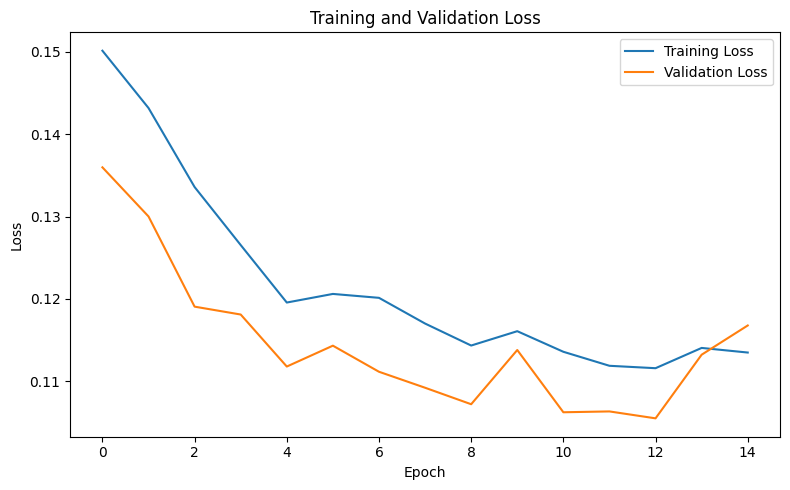

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.savefig('Figure10_LossCurve.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

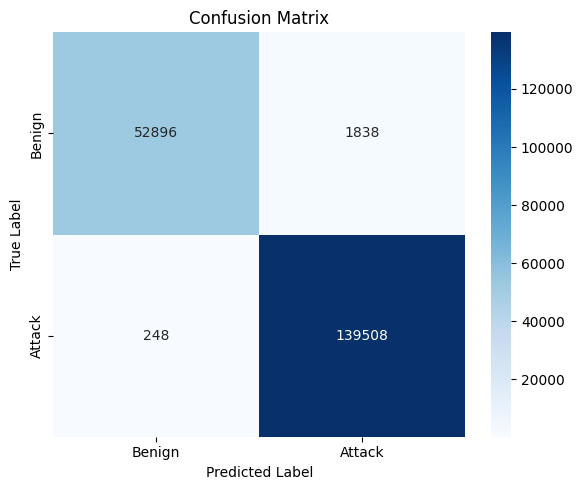

In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign','Attack'],
    yticklabels=['Benign','Attack']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

plt.tight_layout()

plt.savefig(
    'Figure11_ConfusionMatrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

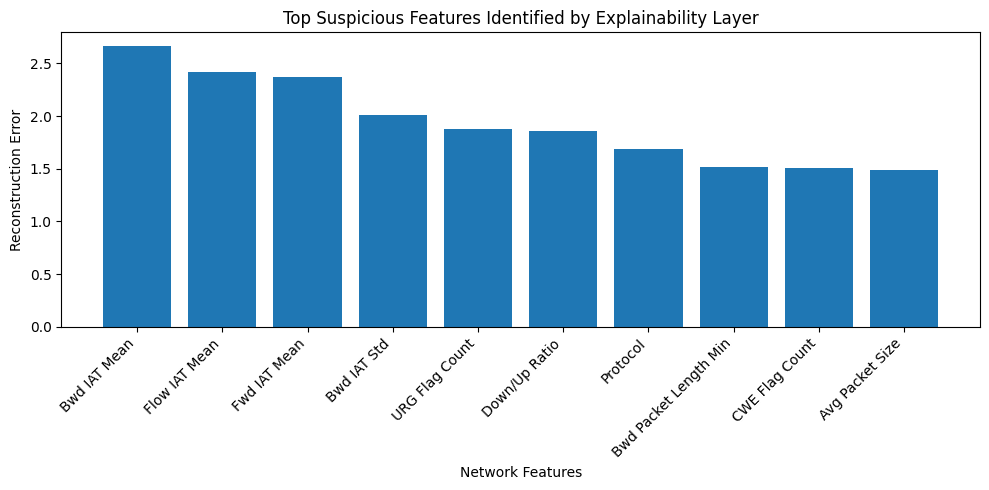

In [35]:
import matplotlib.pyplot as plt

top_features = feature_error_df.head(10)

plt.figure(figsize=(10,5))

plt.bar(
    top_features['Feature'],
    top_features['Reconstruction_Error']
)

plt.xticks(rotation=45,
           ha='right')

plt.ylabel('Reconstruction Error')

plt.xlabel('Network Features')

plt.title(
    'Top Suspicious Features Identified by Explainability Layer'
)

plt.tight_layout()

plt.savefig(
    'Figure12_TopFeatures.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

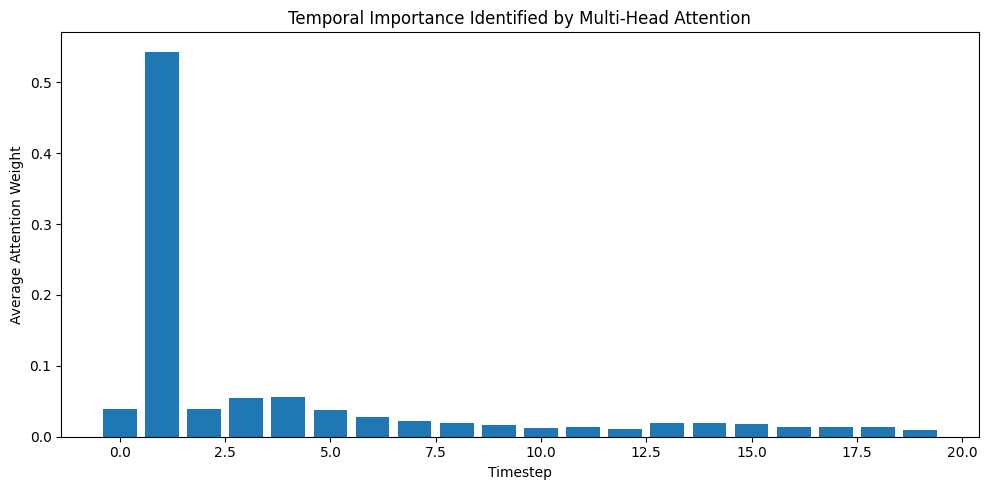

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Average over samples
avg_attention = np.mean(attention_scores, axis=0)

# Average over heads
avg_attention = np.mean(avg_attention, axis=0)

# Importance per timestep
timestep_importance = avg_attention.mean(axis=0)

plt.figure(figsize=(10,5))

plt.bar(
    range(len(timestep_importance)),
    timestep_importance
)

plt.xlabel('Timestep')
plt.ylabel('Average Attention Weight')

plt.title('Temporal Importance Identified by Multi-Head Attention')

plt.tight_layout()

plt.savefig(
    'Temporal_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

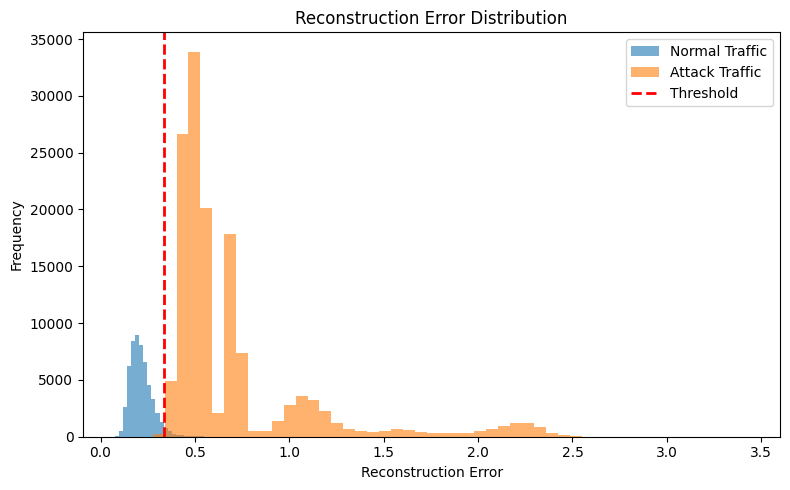

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    train_mae,
    bins=50,
    alpha=0.6,
    label='Normal Traffic'
)

plt.hist(
    attack_mae,
    bins=50,
    alpha=0.6,
    label='Attack Traffic'
)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Threshold'
)

plt.xlabel('Reconstruction Error')

plt.ylabel('Frequency')

plt.title(
    'Reconstruction Error Distribution'
)

plt.legend()

plt.tight_layout()

plt.savefig(
    'Figure14_ReconstructionError.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

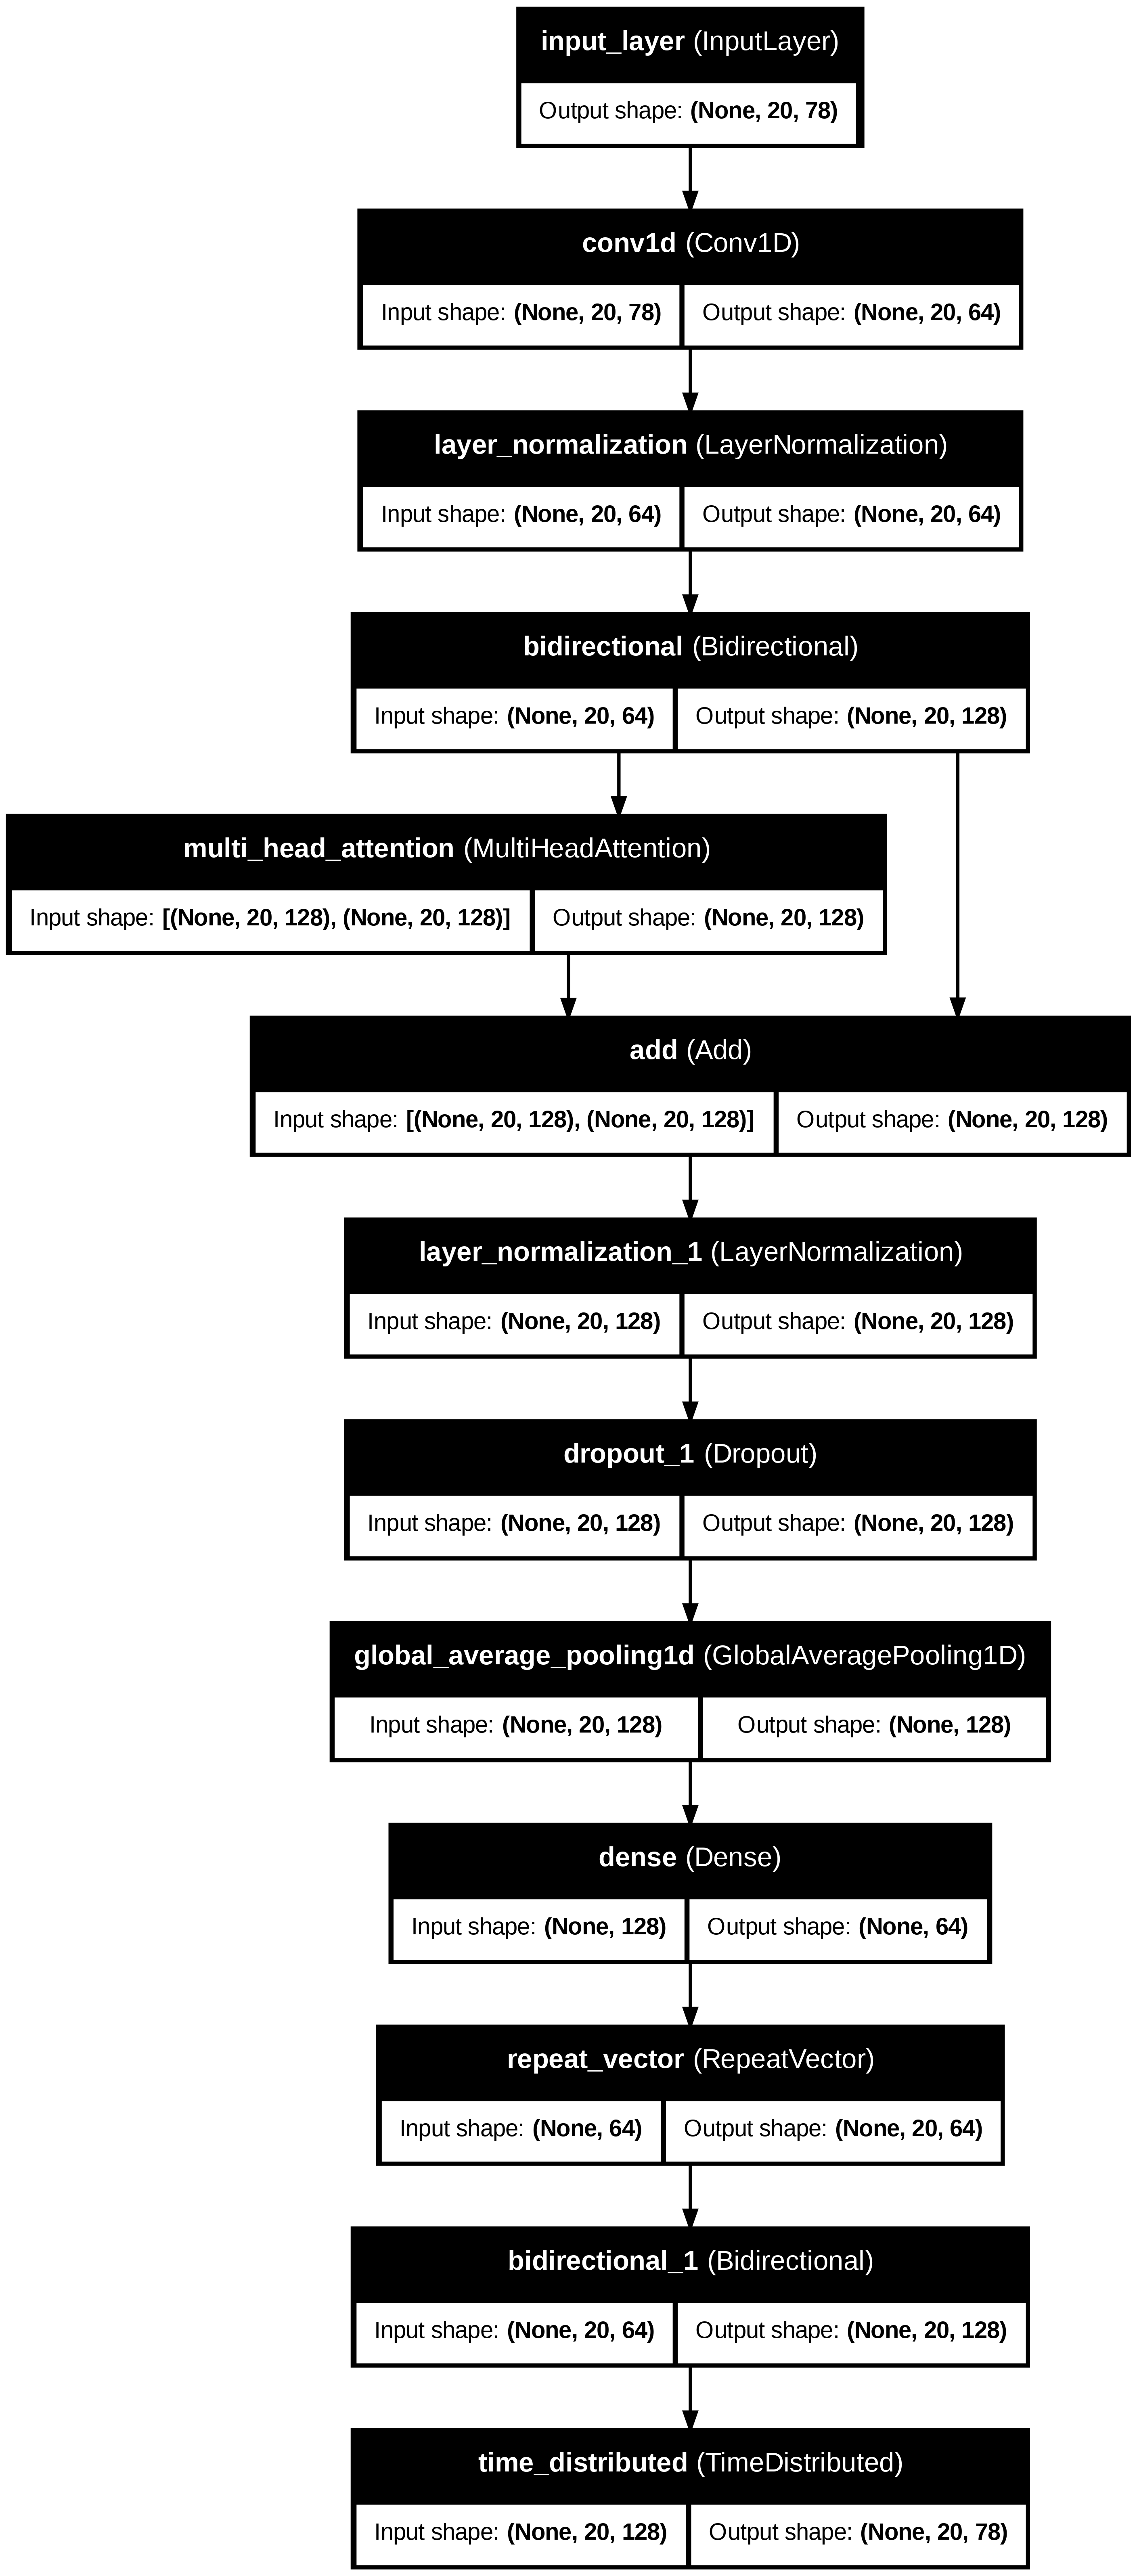

In [38]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
    dpi=300,
    to_file='Figure15_ModelArchitecture.png'
)

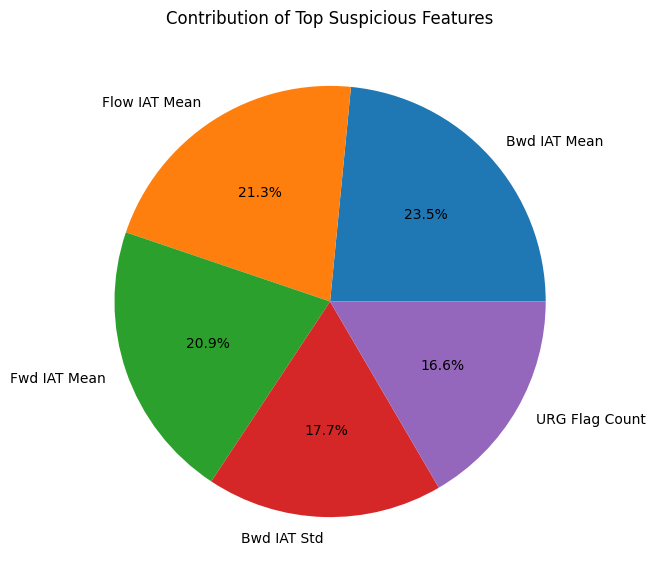

In [39]:
top5 = feature_error_df.head(5)

plt.figure(figsize=(7,7))

plt.pie(
    top5['Reconstruction_Error'],
    labels=top5['Feature'],
    autopct='%1.1f%%'
)

plt.title(
    'Contribution of Top Suspicious Features'
)

plt.savefig(
    'Figure16_FeatureContribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()